In [1]:
import pandas as pd
from sklearn.naive_bayes import BernoulliNB
from sklearn.preprocessing import LabelEncoder

In [2]:
data = pd.read_csv("Social_Network_Ads (1).csv")
data

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [3]:
data = data[['Age', 'EstimatedSalary', 'Purchased']].dropna()

In [4]:
x = data[['Age', 'EstimatedSalary']]
x

,Age,EstimatedSalary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000
...,...,...
395,46,41000
396,51,23000
397,50,20000
398,36,33000


In [6]:
y=data['Purchased']
y

,Purchased
0,0
1,0
2,0
3,0
4,0
...,...
395,1
396,1
397,1
398,0


In [5]:
x=(x>x.mean()).astype(int)

In [9]:
le = LabelEncoder()
y = le.fit_transform(y)

In [10]:
model = BernoulliNB()
model.fit(x,y)

BernoulliNB()

In [11]:
age = int(input("Enter Age: "))
salary = float(input("Enter Estimated Salary: "))

new_data = [[ int(age > data['Age'].mean()),
int(salary > data['EstimatedSalary'].mean())]]

prediction = model.predict(new_data)

if prediction[0] == 1:
    print("Purchase Prediction: Yes")
else:
    print("Purchase Prediction: No")

Enter Age: 30
Enter Estimated Salary: 50000
Purchase Prediction: No


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but BernoulliNB was fitted with feature names
  warnings.warn(


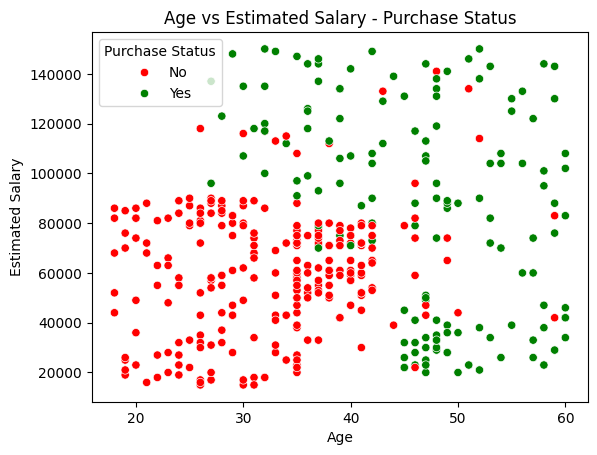

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns
data["Purchase Status"] = data["Purchased"].map({0: "No", 1: "Yes"})
sns.scatterplot(
    data=data,
    x="Age",
    y="EstimatedSalary",
    hue="Purchase Status",
    palette={"No": "red", "Yes": "green"}
)
plt.title("Age vs Estimated Salary - Purchase Status")
plt.xlabel("Age")
plt.ylabel("Estimated Salary")
plt.show()